In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mpltransforms
from matplotlib.ticker import MultipleLocator

import seaborn as sns
import os
import datetime
import pickle


from scipy.signal import find_peaks
from sklearn.mixture import GaussianMixture
from astropy.stats.circstats import circvar, circmean
from scipy.stats import pearsonr
from scipy.stats import entropy
from scipy import stats


from scipy.stats import ranksums, ttest_ind, ttest_rel, f_oneway, false_discovery_control, mannwhitneyu
import statsmodels.regression as sm
from statannotations.Annotator import Annotator

from pycircstat2.hypothesis import wheeler_watson_test, watson_u2_test
from pycircstat2 import Circular

In [3]:
if os.getcwd().endswith('/notebooks/figures'):
    os.chdir('../../')

In [4]:
from src.dataproc import utils, ccutils
from src.model import linearreg

### Supporting functions

In [5]:
# color palette of bars in the MSE plot
colornums = sns.color_palette(palette='Blues', n_colors=6, as_cmap=False)
blues_palette_hex = list(colornums.as_hex())

### Stimulation

In [6]:
save_flag = False

In [7]:
fname_format = 'data/RNSdata/NPEhistograms/%s_Histogram_Hourly.csv'
patcodes_path = 'data/RNSdata/Outcome/Hippo_outcomes_postprocessed_2025April08.csv'
longi_patcodes_path = 'data/RNSdata/Outcome/Hippo_longitudinal_outcomes_postprocessed_2025April08.csv'
lsdf_path = 'data/processed/lscycles/plv_postproc_interval/%s.csv'  # interval or not?

outfig_dir = 'output/circpaper_figures/fig02/'
outsupfig_dir = 'output/circpaper_figures/supp/'

if (not os.path.exists(outfig_dir)) and (save_flag):
    os.mkdir(outfig_dir)
    print('Created a new directory.')

In [8]:
outcome_type = 'wtavg_perc_szred'

patcodesdf = pd.read_csv(patcodes_path)

patcodesdf['sz_red'] = patcodesdf[outcome_type].apply(lambda x: -x/100 if x < 0 else 0)

patient_list = ccutils.final_patient_list()

patoutcome_cols = ['npe_code', 'sz_red']

lgpatcodesdf = pd.read_csv(longi_patcodes_path) # longitudinal outcomes

In [9]:
dfdict = {}

npe0041_date_format = "%m/%d/%y %H:%M"

for patient_id in patient_list:
    fname = fname_format %(patient_id)
    if not os.path.exists(fname):
        print(f'{patient_id}: Histogram file doesnt exist.')
        continue
        
    df = pd.read_csv(fname)
    
    if patient_id == 'NPE0041': # update the formatting of time bins for this patient
        df['Region start time'] = df['Region start time'].apply(lambda x: datetime.datetime.strptime(x, npe0041_date_format).isoformat(sep=' '))
    
    df['Local_hour'] = df['Region start time'].apply(lambda x: datetime.datetime.fromisoformat(x).hour)
    df['npe_code'] = patient_id
    df['sz_red'] = patcodesdf.loc[patcodesdf['npe_code']==patient_id].sz_red.item()
    df['RX_norm'] = (df['Episode starts with RX'] - df['Episode starts with RX'].mean()) / df['Episode starts with RX'].std()
    max_hour = df.groupby(by='Local_hour')['Episode starts with RX'].mean().idxmax()
    df['Maxalgn_hour'] = (df['Local_hour'] - max_hour)  % 24
    df['Maxalgn_mid_hour'] = ( df['Maxalgn_hour'] - 12 ) % 24
    
    # time from implantation
    implantdt = datetime.datetime.fromisoformat(patcodesdf.loc[patcodesdf['npe_code']==patient_id]['implant_date'].item())
    utils.tfromstart_days(df, datecol='Region start time', start_date=implantdt)
    ccutils.round_half_year_days(df)
    
    dfdict[patient_id] = df.copy()

In [10]:
MIN_LS_NSAMP = 120   # 120 MAGIC for interval LS models, 0 otherwise
lsdata_cols = ['amp_unnorm_%s', 'amp_norm_%s', 'peakhour_%s', 'fitpower_%s', 'pvalue_%s']


# read the cycle charateristics csv file and store in a dictionary
lsdf_dict = {}

for patient_id in patient_list:
    
    if not os.path.exists(lsdf_path % (patient_id)):
        print(f'{patient_id}: No LS file found. Removing from patient list.')
        continue
    
    lsdf = pd.read_csv(lsdf_path % (patient_id))  # read Ls file
    
    pat_days_list = [int(item.split('_')[-1]) for item in lsdf.columns if ('nsamp' in item)]
    
    # blank out times with samples less than some threshold
    for daynum in pat_days_list:
        if lsdf[f'nsamp_{daynum}'].iloc[0] < MIN_LS_NSAMP:
            pat_lsdata_cols = [item%(daynum) for item in lsdata_cols]
            lsdf[pat_lsdata_cols] = np.NaN
    
    # store the dataframe
    lsdf_dict[patient_id] = lsdf.copy()
    

In [11]:
feature_list = lsdf_dict[patient_list[0]]['feature'].to_list()
band_list = ['theta', 'alpha', 'beta', 'gamma']
edge_type_list = ['local']  # local FC, long-range FC, both FCs

subfeatdict = ccutils.get_subfeatdict(feature_list, band_list, edge_type_list)

print('Verify the number of features of each type in the dict:')
print([len(subfeatdict[keyval1][keyval2]) for keyval1 in subfeatdict.keys() 
       for keyval2 in subfeatdict[keyval1].keys()])

Verify the number of features of each type in the dict:
[2, 2, 2, 2, 8]


In [12]:
normtype = 'zeroone'  # 'zeroone', 'maxnorm'
lgmscdict = ccutils.mean_stimcounts(dfdict, patient_list, groupby=['dur_halfyr', 'Local_hour'], 
                                    normtype=normtype)

In [13]:
interval_start = 7   # MAGIC; change based on normtype. zeroone=7, maxnorm=5
interval_end = 11

lgaucdf = ccutils.longi_interval_aucdf(lgmscdict, patient_list, interval_start, interval_end, verbose=True)

Dropped entries because stim AUC=0: # 9


## A: Longitudinal Outcomes

In [14]:
# outcome for patients included in the analysis
outcomedf = lgpatcodesdf.loc[lgpatcodesdf['npe_code'].isin(patient_list)].copy()
outcomedf['yrs_from_implant'] = outcomedf['days_from_implant'].apply(lambda x: round(x / 365,1))

ccutils.round_half_year_days(outcomedf, colname='days_from_implant')
print('Output ready.')

Output ready.


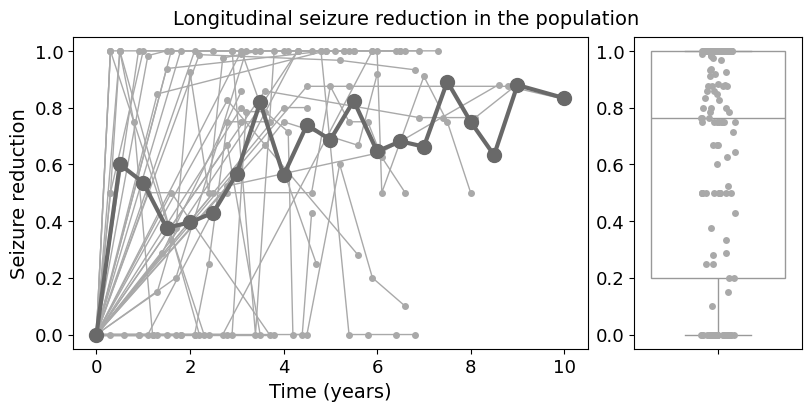

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(8,4), width_ratios=[4,1.3], 
                       layout='constrained')

#### longitudinal traces
# individual patient traces
for patid in patient_list:
    meas_days = np.concatenate(([0], outcomedf.loc[outcomedf['npe_code']==patid]['yrs_from_implant'].values))
    meas_szred = np.concatenate(([0], outcomedf.loc[outcomedf['npe_code']==patid]['sz_red'].values))
    
    ax[0].plot(meas_days, meas_szred, 
             color='darkgray', linewidth=1, marker='o', markersize=4)
    
# average trace
pop_meas = outcomedf.groupby(by='dur_halfyr')['sz_red'].mean()
pop_meas_yrs  = np.round( np.concatenate(([0], pop_meas.index)) / 365, 1)
pop_meas_szred = np.concatenate(([0], pop_meas.values))

ax[0].plot(pop_meas_yrs, pop_meas_szred, 
         color='dimgrey', linewidth=3, marker='o', markersize=10)

ax[0].set_xlabel('Time (years)', fontsize=14)
ax[0].set_ylabel('Seizure reduction', fontsize=14)
ax[0].tick_params(labelsize=13)

#### boxplot
sns.boxplot(data=outcomedf, y='sz_red', color='white', ax=ax[1])
sns.stripplot(data=outcomedf, y='sz_red', color='darkgray', ax=ax[1])
ax[1].set_ylabel('')
ax[1].tick_params(labelsize=13)

fig.suptitle('Longitudinal seizure reduction in the population', fontsize=14)

if save_flag:
    fig.savefig(outfig_dir + 'longitudinal_outcomes.pdf', dpi=300)
    
plt.show()

fig.clear()

In [16]:
# statistics
print('number of visits: mean=', outcomedf['npe_code'].value_counts().mean(), 
      'std:', outcomedf['npe_code'].value_counts().std())

print('inter-visit interval: mean=', outcomedf['visit_interval'].mean(), 'std:', outcomedf['visit_interval'].std())


number of visits: mean= 3.8157894736842106 std: 2.0905871819399473
inter-visit interval: mean= 448.0896551724138 std: 404.4344974646247


## FC-CC and stimulation with outcome

In [17]:
band_list = ['theta', 'alpha', 'beta', 'gamma']
edge_type_list = ['local']
tltype = 'causal'  # 'causal' or 'noncausal'
mreg_id_vars = ['npecode', 'feat_days', 'baseline_seizure_rate', 'outcome_days', 'sz_red', 
                'auc', 'auc_interval', 'auc_converse', 'max_hour', 'sin_hour', 'cos_hour']
mreg_value_vars = ['amp_unnorm_local', 'peakhour_local']

# FC-CC features
lgfeatdf = ccutils.create_lgfcccfeat_dataframe(lsdf_dict, patient_list, band_list, edge_type_list, subfeatdict)

# combine stimulation feature with FC-CC features
lgfeatdf = lgaucdf.merge(lgfeatdf, how='left', left_on=['npecode', 'dur_day'],
                     right_on=['npecode', 'days_from_implant'])

# combine features with seizure reduction information
mregdf = ccutils.create_cop_dataframe(lgpatcodesdf, lgfeatdf, patient_list, mreg_id_vars, mreg_value_vars, tltype, 
                                      verbose=True)

Dropped nans in regdf: 0


### recursive feature selection

In [18]:
# recusive feature elimination for a range of feature sets

feat_sz = ['log_baseline_seizure_rate']

feat_fccc_amp = ['amp_unnorm_local-theta', 'amp_unnorm_local-alpha', 
                 'amp_unnorm_local-beta', 'amp_unnorm_local-gamma']

feat_fccc_ps = ['peakhour_local-theta', 'peakhour_local-alpha', 
                'peakhour_local-beta', 'peakhour_local-gamma']

feat_stim = ['auc_interval', 'auc_converse', 'sin_hour', 'cos_hour']

feat_all = feat_sz + feat_fccc_amp + feat_fccc_ps + feat_stim

fullfeatdict = {'sz': feat_sz , 'fccc_amp': feat_fccc_amp, 'fccc_ps': feat_fccc_ps, 
                'fccc': feat_fccc_amp + feat_fccc_ps, 'stim': feat_stim, 'all': feat_all}

yvar = 'sz_red'

rfefeatdict = {}

for featkey, regfeats in fullfeatdict.items():
    print(featkey)
    # recursive feature elimination
    final_regfeats = linearreg.recursive_feature_elimination(regdf=mregdf, full_feature_list=regfeats, yvar=yvar, 
                                                             cv_folds_list=patient_list, cv_var='npecode', 
                                                             remove_outliers=False)

    print('Final feature list:', final_regfeats)
    
    # store the features
    rfefeatdict[featkey] = final_regfeats

sz
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 log_baseline_seizure_rate__pvalue    0
dtype: int64
Final feature list: []
fccc_amp
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 amp_unnorm_local-theta__pvalue    0
amp_unnorm_local-alpha__pvalue    0
amp_unnorm_local-beta__pvalue     0
amp_unnorm_local-gamma__pvalue    0
dtype: int64
Final feature list: []
fccc_ps
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 peakhour_local-theta__pvalue     1
peakhour_local-alpha__pvalue    30
peakhour_local-beta__pvalue      0
peakhour_local-gamma__pvalue     0
dtype: int64
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.


Significance counts of each feature:


 peakhour_local-theta__pvalue     5
peakhour_local-alpha__pvalue    30
dtype: int64
Final feature list: ['peakhour_local-theta', 'peakhour_local-alpha']
fccc
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 amp_unnorm_local-theta__pvalue     0
amp_unnorm_local-alpha__pvalue     0
amp_unnorm_local-beta__pvalue      0
amp_unnorm_local-gamma__pvalue     1
peakhour_local-theta__pvalue       2
peakhour_local-alpha__pvalue      30
peakhour_local-beta__pvalue        1
peakhour_local-gamma__pvalue       0
dtype: int64
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 amp_unnorm_local-gamma__pvalue    27
peakhour_local-theta__pvalue       2
peakhour_local-alpha__pvalue      30
peakhour_local-beta__pvalue        0
dtype: int64
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
Significance c

Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 auc_converse__pvalue    30
sin_hour__pvalue         0
dtype: int64
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 auc_converse__pvalue    30
dtype: int64
Final feature list: ['auc_converse']
all
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 log_baseline_seizure_rate__pvalue     5
amp_unnorm_local-theta__pvalue        0
amp_unnorm_local-alpha__pvalue        0
amp_unnorm_local-beta__pvalue         0
amp_unnorm_local-gamma__pvalue       23
peakhour_local-theta__pvalue          1
peakhour_local-alpha__pvalue         24
peakhour_local-beta__pvalue           0
peakhour_local-gamma__pvalue          0
auc_interval__pvalue                  0
auc_converse__pvalue                 30
sin_hour__pvalue                      0
cos_hour__pvalu

In [19]:
## include baseline seizure rate
rfefeatdict['sz'] = ['log_baseline_seizure_rate']

yvar = 'sz_red'


gppreddf = []  # all the predictions for all the feature sets
gpmsedf = []   # MSE for each fold for all the feature sets
cmmsedf = []   # grand total MSE (combined MSE) for all the feature sets
cmllfdf = []   # combined log likelihood of trained model for all the feature sets

for featkey, regfeats in rfefeatdict.items():
    
    print(f'\n{featkey}')
    
    # linear regression cross-validation
    lmpreddf, linmoddict = linearreg.cross_validation(regdf=mregdf, regfeat_cols=regfeats, yvar=yvar, 
                                                     cv_folds_list=patient_list, cv_var='npecode', 
                                                     remove_outliers=False)
    
    # store predictions
    if featkey == 'sz':
        gppreddf.append(lmpreddf.rename(columns={'modpred':featkey}))
    else:
        gppreddf.append(lmpreddf['modpred'].rename(featkey))
    
    # compute MSE
    if featkey == 'sz':
        diff_tuples = [('gt','modpred', f'{featkey}_mse'), ('gt','basemean','base_mse')]
    else:
        diff_tuples = [('gt','modpred', f'{featkey}_mse')]
        
    lmmsedf = linearreg.foldwise_mse(preddf=lmpreddf, cv_var='npecode', diff_tuples=diff_tuples)
    
    feat_cmmsedf = linearreg.combined_mse(preddf=lmpreddf, diff_tuples=diff_tuples)
    
    gpmsedf.append(lmmsedf.copy())
    cmmsedf.append(feat_cmmsedf)
    
    # number of times a coefficient was significant
    lmsummary = linearreg.summarize_model_cv(linmoddict, cv_var='npecode')
    print((lmsummary[[item for item in lmsummary.columns if '__pvalue' in item]] < 0.05).sum())
    
    # combined loglikeihood of training data
    cmllfdf.append(pd.DataFrame({featkey: [linearreg.combined_llf(linmoddict)]}))

# concatenate
gppreddf = pd.concat(gppreddf, axis=1, ignore_index=False)
gpmsedf = pd.concat(gpmsedf, axis=1, ignore_index=False)
cmmsedf = pd.concat(cmmsedf, axis=1, ignore_index=False)
cmllfdf = pd.concat(cmllfdf, axis=1, ignore_index=False)


sz
Outliers NOT removed. Num entries: 72.


Clipped output between 0-1.
Cross-validation complete.
log_baseline_seizure_rate__pvalue     0
const__pvalue                        30
dtype: int64

fccc_amp
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
const__pvalue    30
dtype: int64

fccc_ps
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
peakhour_local-theta__pvalue     5
peakhour_local-alpha__pvalue    30
const__pvalue                   30
dtype: int64



fccc
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
amp_unnorm_local-gamma__pvalue    28
peakhour_local-theta__pvalue       2
peakhour_local-alpha__pvalue      30
const__pvalue                     30
dtype: int64

stim
Outliers NOT removed. Num entries: 72.


/Users/saboo/Projects/pub-2026-circadian-cycle-rns-control/src/model/linearreg.py:105: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  modmsedf = preddf.groupby(by=cv_var).apply(lambda x: ((x[tup[0]] - x[tup[1]]) ** 2).mean() )
/Users/saboo/Projects/pub-2026-circadian-cycle-rns-control/src/model/linearreg.py:105: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  modmsedf = preddf.groupby(by=cv_var).apply(lambda x: ((x[tup[

Clipped output between 0-1.
Cross-validation complete.
auc_converse__pvalue    30
const__pvalue           30
dtype: int64

all
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
log_baseline_seizure_rate__pvalue     3
amp_unnorm_local-gamma__pvalue       27
peakhour_local-theta__pvalue         27
peakhour_local-alpha__pvalue         28
auc_converse__pvalue                 30
const__pvalue                        30
dtype: int64


/Users/saboo/Projects/pub-2026-circadian-cycle-rns-control/src/model/linearreg.py:105: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  modmsedf = preddf.groupby(by=cv_var).apply(lambda x: ((x[tup[0]] - x[tup[1]]) ** 2).mean() )
/Users/saboo/Projects/pub-2026-circadian-cycle-rns-control/src/model/linearreg.py:105: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  modmsedf = preddf.groupby(by=cv_var).apply(lambda x: ((x[tup[

In [20]:
rfefeatdict

{'sz': ['log_baseline_seizure_rate'],
 'fccc_amp': [],
 'fccc_ps': ['peakhour_local-theta', 'peakhour_local-alpha'],
 'fccc': ['amp_unnorm_local-gamma',
  'peakhour_local-theta',
  'peakhour_local-alpha'],
 'stim': ['auc_converse'],
 'all': ['log_baseline_seizure_rate',
  'amp_unnorm_local-gamma',
  'peakhour_local-theta',
  'peakhour_local-alpha',
  'auc_converse']}

### C: Clinical Prediction MSE

In [21]:
cmmsedf_norm = 100 * (cmmsedf['base_mse'].item() - cmmsedf) / cmmsedf['base_mse'].item()
mse_xtldict = {'sz': 'Sz.', 'fccc_amp': 'CA', 'fccc_ps': 'CC', 
               'fccc': 'CA and CC', 'stim': 'Stimulation', 'all': 'All'}


In [22]:
### correlation values
# for key in [item for item in gppreddf.columns if (item != 'npecode') and (item != 'gt')]:
#     print(key, '\t', pearsonr(gppreddf['gt'], gppreddf[key]))

/var/folders/gd/6nx8h5_s2pl0kp6dz_b6wn300000gn/T/ipykernel_46261/463025167.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels=[mse_xtldict[item.split('_mse')[0]] for item in feature_set_list])


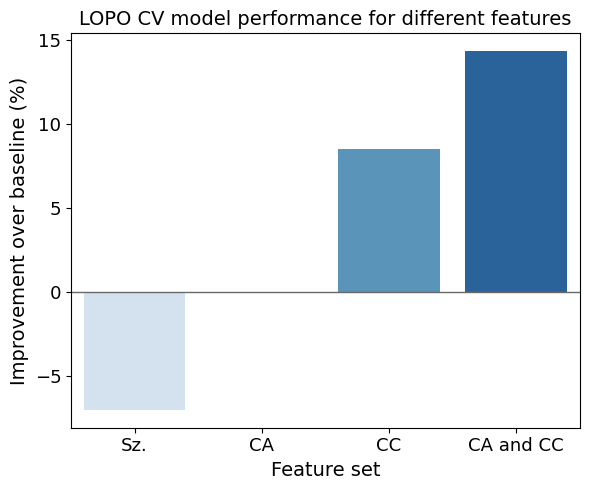

In [23]:
feature_set_list = ['sz_mse', 'fccc_amp_mse', 'fccc_ps_mse', 'fccc_mse']

fig, ax = plt.subplots(1,1, figsize=(6,5))
sns.barplot(cmmsedf_norm[feature_set_list], 
            palette='Blues', ax=ax)

ax.axhline(y=0, linewidth=1, color='dimgray')

ax.set_xticklabels(labels=[mse_xtldict[item.split('_mse')[0]] for item in feature_set_list])
ax.set_xlabel('Feature set', fontsize=14)
ax.set_ylabel('Improvement over baseline (%)', fontsize=14)
ax.tick_params(labelsize=13)

ax.set_title('LOPO CV model performance for different features', fontsize=14)

fig.tight_layout()

if save_flag:
    fig.savefig(outfig_dir + 'clinpred_mse_fccconly.pdf', dpi=300)

plt.show()


In [24]:
cmmsedf_norm

,sz_mse,base_mse,fccc_amp_mse,fccc_ps_mse,fccc_mse,stim_mse,all_mse
0,-7.032215,0.0,0.0,8.511234,14.310578,11.508901,21.285418


## E (Option 1): Predicted vs observed seizure reduction scatter plot

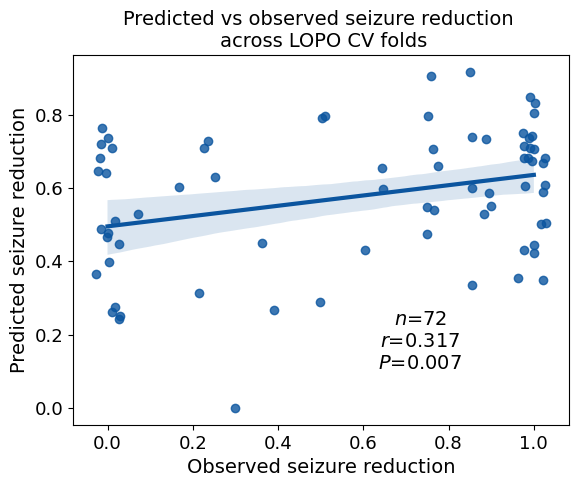

In [25]:
corrval = pearsonr(gppreddf['gt'], gppreddf['fccc'])    # using gppreddf because it has observed and predicted values for all RFE feature subsets

# model prediction
ax = sns.regplot(data=gppreddf, x='gt', y='fccc', label='Model prediction', 
                 color=blues_palette_hex[5], line_kws={'linewidth':3}, x_jitter=0.03)

# # baseline
# sns.regplot(data=fccc_lmpreddf, x='gt', y='basemean', label='Baseline', 
#             color='dimgray', scatter_kws={'alpha':0.5}, 
#             line_kws={'alpha':0.5, 'linewidth':2, 'linestyle':'--'})

# annotations
ax.text(x=0.7, y=0.15, s='$n$=%d\n$r$=%0.3f\n$P$=%0.3f'%(gppreddf.shape[0], 
                                                     corrval.statistic, corrval.pvalue), 
        transform=ax.transAxes, fontsize=14, color='black', ha='center')

# aesthetics
ax.set_xlabel('Observed seizure reduction', fontsize=14)
ax.set_ylabel('Predicted seizure reduction', fontsize=14)
ax.tick_params(labelsize=13)

# ax.legend(fontsize=14, loc=2)

ax.set_title('Predicted vs observed seizure reduction \n across LOPO CV folds', fontsize=14)

if save_flag:
    plt.savefig(outfig_dir + 'clinpred_scatter_fccc.pdf', dpi=300)

plt.show()

### D: Model weights for FC-CC features model

In [26]:
# visualization of model weights for the model with all the features

# note that this is with all the features of FCCC, not the ones selected by RFE -- so dont use it for 
fccc_lmpreddf, fccc_linmoddict = linearreg.cross_validation(regdf=mregdf, regfeat_cols=rfefeatdict['fccc'], yvar=yvar, 
                                                            cv_folds_list=patient_list, cv_var='npecode', 
                                                            remove_outliers=False)
    
# number of times a coefficient was significant
fccc_lmsummary = linearreg.summarize_model_cv(fccc_linmoddict, cv_var='npecode')
print((fccc_lmsummary[[item for item in fccc_lmsummary.columns if '__pvalue' in item]] < 0.05).sum())

Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
amp_unnorm_local-gamma__pvalue    28
peakhour_local-theta__pvalue       2
peakhour_local-alpha__pvalue      30
const__pvalue                     30
dtype: int64


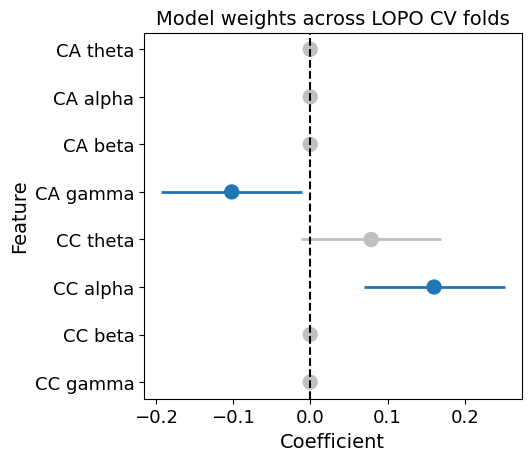

In [27]:
fccc_effectsize = linearreg.effect_size_across_folds(fccc_lmsummary)
fccc_effectsize = utils.include_excluded_features_in_effectsize_df(fccc_effectsize, fullfeatdict['fccc'])  # effectsize of excluded variables

mcoef_ytldict = {'amp_unnorm_local-theta': 'CA theta',
                 'amp_unnorm_local-alpha': 'CA alpha',
                 'amp_unnorm_local-beta': 'CA beta',
                 'amp_unnorm_local-gamma': 'CA gamma',
                 'peakhour_local-theta': 'CC theta',
                 'peakhour_local-alpha': 'CC alpha',
                 'peakhour_local-beta': 'CC beta',
                 'peakhour_local-gamma': 'CC gamma'}
escolordict = {1:'tab:blue', -1:'silver'}

fig, ax = plt.subplots(1,1, figsize=(5.2, 4.5), layout='constrained')

ax.scatter(fccc_effectsize['coef'].values, fccc_effectsize['xticks'].values, s=100, 
           c=[escolordict[item] for item in fccc_effectsize['sig'].values])
ax.hlines(y=fccc_effectsize['xticks'].values, xmin=fccc_effectsize['lower'].values, xmax=fccc_effectsize['upper'].values, 
             linewidth=2, colors=[escolordict[item] for item in fccc_effectsize['sig'].values])
ax.axvline(x=0, color='black', linestyle='--')
ax.set_yticks(ticks=fccc_effectsize['xticks'].values, 
              labels=[mcoef_ytldict[item] for item in fccc_effectsize.index], fontsize=13)

ax.set_ylabel('Feature', fontsize=14)
ax.set_xlabel('Coefficient', fontsize=14)
ax.tick_params(labelsize=13)
ax.set_title('Beta weights', fontsize=14)

ax.set_title('Model weights across LOPO CV folds', fontsize=14)

if save_flag:
    # plt.savefig(outsupfig_dir + 'circbio_clinpred_modelcoef_fccc_after_RFE.pdf', dpi=300)
    plt.savefig(outfig_dir + 'clinpred_modelcoef_fccc_after_RFE.pdf', dpi=300)

plt.show()

### Fig 4E: All features for outcome prediction

/var/folders/gd/6nx8h5_s2pl0kp6dz_b6wn300000gn/T/ipykernel_46261/3487916856.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels=[mse_xtldict[item.split('_mse')[0]] for item in feature_set_list])


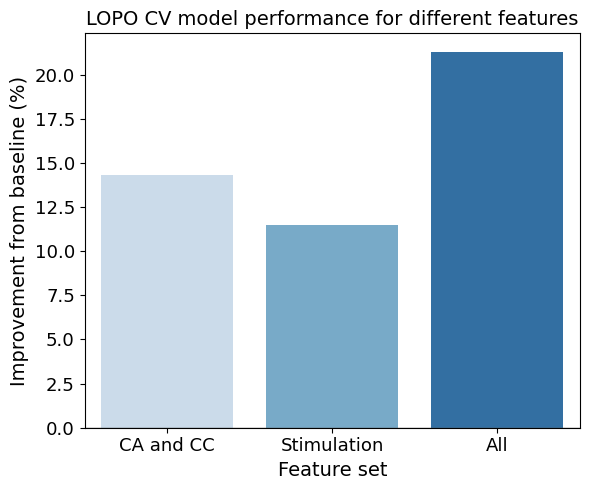

In [28]:
feature_set_list = ['fccc_mse', 'stim_mse', 'all_mse']

fig, ax = plt.subplots(1,1, figsize=(6,5))
sns.barplot(cmmsedf_norm[feature_set_list], 
            palette='Blues', ax=ax)

ax.axhline(y=0, linewidth=1, color='dimgray')

ax.set_xticklabels(labels=[mse_xtldict[item.split('_mse')[0]] for item in feature_set_list])
ax.set_xlabel('Feature set', fontsize=14)
ax.set_ylabel('Improvement from baseline (%)', fontsize=14)
ax.tick_params(labelsize=13)

ax.set_title('LOPO CV model performance for different features', fontsize=14)

fig.tight_layout()

if save_flag:
    fig.savefig('output/circpaper_figures/fig04/clinpred_mse_fcccstim.pdf', dpi=300)

plt.show()


### 4E Supplement: All feature model weights

In [29]:
# visualization of model weights for the model with all the features
 
all_lmpreddf, all_linmoddict = linearreg.cross_validation(regdf=mregdf, regfeat_cols=rfefeatdict['all'], yvar=yvar, 
                                                          cv_folds_list=patient_list, cv_var='npecode', 
                                                          remove_outliers=False)
    
# number of times a coefficient was significant
all_lmsummary = linearreg.summarize_model_cv(all_linmoddict, cv_var='npecode')
print((all_lmsummary[[item for item in all_lmsummary.columns if '__pvalue' in item]] < 0.05).sum())

Outliers NOT removed. Num entries: 72.


Clipped output between 0-1.
Cross-validation complete.
log_baseline_seizure_rate__pvalue     3
amp_unnorm_local-gamma__pvalue       27
peakhour_local-theta__pvalue         27
peakhour_local-alpha__pvalue         28
auc_converse__pvalue                 30
const__pvalue                        30
dtype: int64


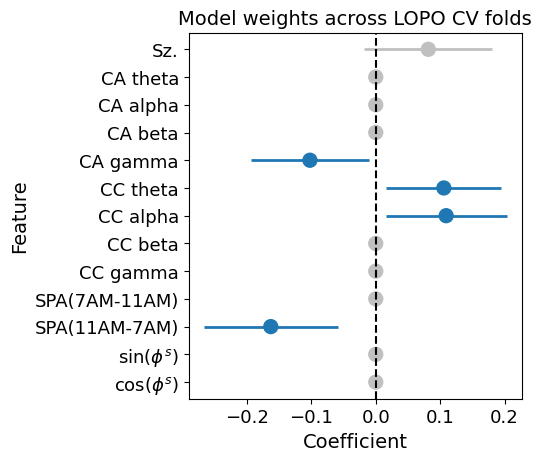

In [30]:
effectsize = linearreg.effect_size_across_folds(all_lmsummary)
effectsize = utils.include_excluded_features_in_effectsize_df(effectsize, fullfeatdict['all'])  # effectsize of excluded variables

mcoef_ytldict = {'log_baseline_seizure_rate': 'Sz.', 
                 'amp_unnorm_local-theta': 'CA theta',
                 'amp_unnorm_local-alpha': 'CA alpha',
                 'amp_unnorm_local-beta': 'CA beta',
                 'amp_unnorm_local-gamma': 'CA gamma',
                 'peakhour_local-theta': 'CC theta',
                 'peakhour_local-alpha': 'CC alpha',
                 'peakhour_local-beta': 'CC beta',
                 'peakhour_local-gamma': 'CC gamma',
                 'auc_interval': 'SPA(7AM-11AM)',
                 'auc_converse': 'SPA(11AM-7AM)',
                 'sin_hour': 'sin($\phi^{s}$)',
                 'cos_hour': 'cos($\phi^{s}$)'}
escolordict = {1:'tab:blue', -1:'silver'}


fig, ax = plt.subplots(1,1, figsize=(5.2, 4.5), layout='constrained')


ax.scatter(effectsize['coef'].values, effectsize['xticks'].values, s=100, 
           c=[escolordict[item] for item in effectsize['sig'].values])
ax.hlines(y=effectsize['xticks'].values, xmin=effectsize['lower'].values, xmax=effectsize['upper'].values, 
             linewidth=2, colors=[escolordict[item] for item in effectsize['sig'].values])
ax.axvline(x=0, color='black', linestyle='--')
ax.set_yticks(ticks=effectsize['xticks'].values, 
              labels=[mcoef_ytldict[item] for item in effectsize.index], fontsize=13)

ax.set_ylabel('Feature', fontsize=14)
ax.set_xlabel('Coefficient', fontsize=14)
ax.tick_params(labelsize=13)
ax.set_title('Beta weights', fontsize=14)

ax.set_title('Model weights across LOPO CV folds', fontsize=14)

if save_flag:
    plt.savefig(outsupfig_dir + 'stim_clinpred_modelcoefs.pdf', dpi=300)

plt.show()

### Supplement: Stimulation lin reg scatter plot

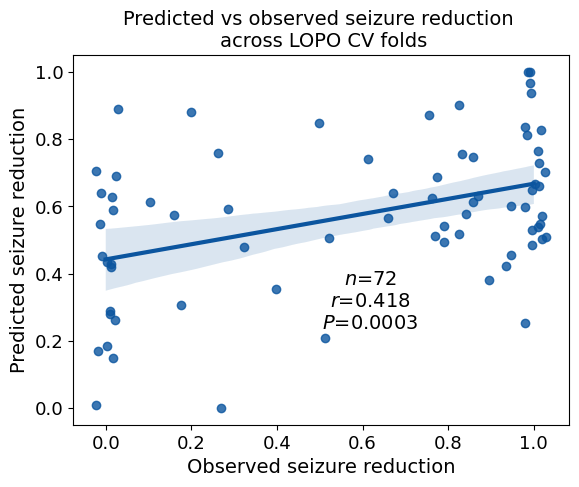

In [31]:
corrval = pearsonr(all_lmpreddf['gt'], all_lmpreddf['modpred'])

# model prediction
ax = sns.regplot(data=all_lmpreddf, x='gt', y='modpred', label='Model prediction', 
                 color=blues_palette_hex[5], line_kws={'linewidth':3}, x_jitter=0.03)

# annotations
ax.text(x=0.6, y=0.26, s='$n$=%d\n$r$=%0.3f\n$P$=%0.4f'%(all_lmpreddf.shape[0], 
                                                     corrval.statistic, corrval.pvalue), 
        transform=ax.transAxes, fontsize=14, color='black', ha='center')

# aesthetics
ax.set_xlabel('Observed seizure reduction', fontsize=14)
ax.set_ylabel('Predicted seizure reduction', fontsize=14)
ax.tick_params(labelsize=13)

# ax.legend(fontsize=14, loc=2)

ax.set_title('Predicted vs observed seizure reduction \n across LOPO CV folds', fontsize=14)

if save_flag:
    plt.savefig(outsupfig_dir + 'stim_clinpred_scatter.pdf', dpi=300)

plt.show()

### Supplement: Sample patients

In [32]:
all_lmpreddf =  pd.concat((all_lmpreddf, mregdf[['outcome_days']]), axis=1, ignore_index=False)

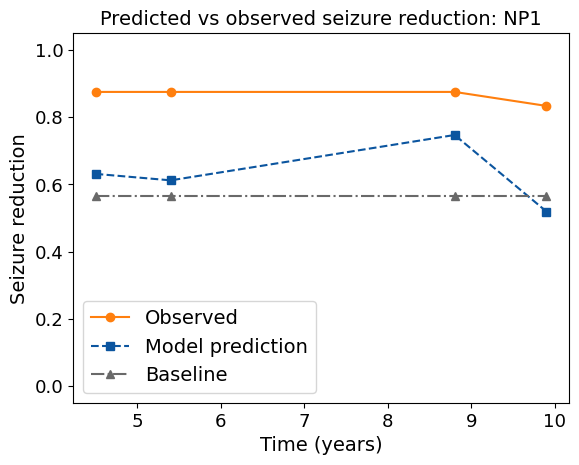

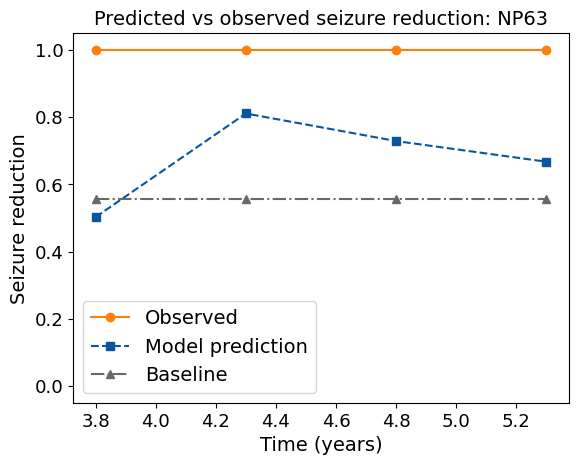

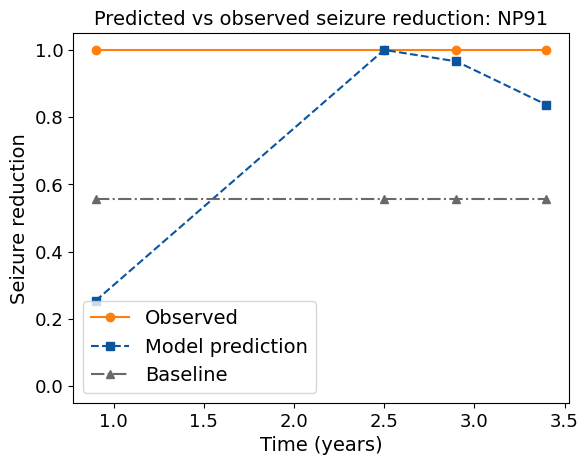

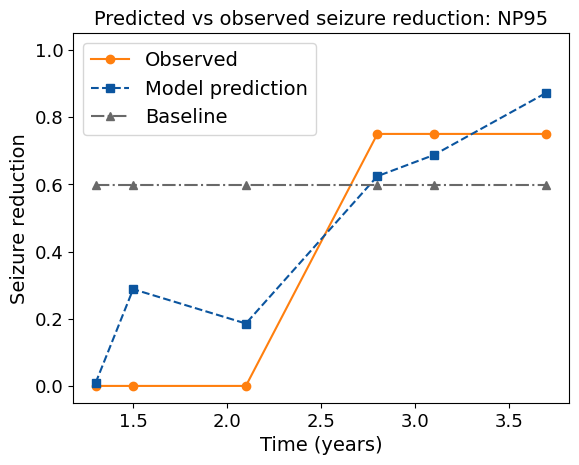

In [33]:
for patid in ['NPE0001', 'NPE0063', 'NPE0091', 'NPE0095']:  # patients to show: NPE0001, NPE0063, NPE0091, NPE0095

    plotdf = all_lmpreddf.loc[all_lmpreddf['npecode']==patid].copy()
    x_values = np.round(plotdf['outcome_days'].values / 365, 1)
    
    plt.plot(x_values, plotdf['gt'].values, 
             color='tab:orange', linestyle='-', marker='o', label='Observed')
    
    plt.plot(x_values, plotdf['modpred'].values, 
             color=blues_palette_hex[5], linestyle='--', marker='s', label='Model prediction')
    
    plt.plot(x_values, plotdf['basemean'].values, 
             color='dimgray', linestyle='-.', marker='^', label='Baseline')
    
    plt.ylim([-0.05, 1.05])
    plt.legend()
    
    plt.xlabel('Time (years)', fontsize=14)
    plt.ylabel('Seizure reduction', fontsize=14)
    plt.tick_params(labelsize=13)
    plt.title(f'Predicted vs observed seizure reduction: {utils.format_patid(patid)}', fontsize=14)
    
    plt.legend(fontsize=14)
    
    if save_flag:
        plt.savefig(outsupfig_dir + f'stim_{patid}_prediction.pdf', dpi=300)
    
    plt.show()